# Phân tích khảo sát đánh giá giao diện người dùng TripGuardian

Notebook đọc CSV UI đã giải nén ở cùng thư mục và vẽ Matplotlib theo phong cách Google Forms. Mỗi câu có hai biểu đồ: **trước lọc** và **sau lọc**.


In [13]:
from pathlib import Path
import re
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.ticker import MaxNLocator

installed_fonts = {f.name for f in fm.fontManager.ttflist}
VIETNAMESE_FONT = next((f for f in ("Arial", "Segoe UI", "Tahoma", "DejaVu Sans") if f in installed_fonts), "sans-serif")
plt.rcParams.update({
    "font.family": VIETNAMESE_FONT,
    "font.sans-serif": [VIETNAMESE_FONT, "Arial", "Segoe UI", "Tahoma", "DejaVu Sans"],
    "font.size": 10, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.unicode_minus": False,
})

DATA_DIR = Path.cwd()
OUTPUT_DIR = DATA_DIR / "tripguardian_ui_charts"
OUTPUT_DIR.mkdir(exist_ok=True)
CSV_FILE = next(DATA_DIR.glob("KHẢO SÁT ĐÁNH GIÁ GIAO DIỆN*.csv"), None)
if CSV_FILE is None:
    raise FileNotFoundError("Không thấy CSV khảo sát UI. Đặt file CSV cạnh notebook rồi chạy lại.")
raw = pd.read_csv(CSV_FILE, encoding="utf-8-sig")
raw.columns = [str(c).strip() for c in raw.columns]
print(f"Font biểu đồ: {VIETNAMESE_FONT}")
print(f"Đã đọc {len(raw)} phản hồi, {len(raw.columns)} cột.")
raw.head(2)


Font biểu đồ: Arial
Đã đọc 49 phản hồi, 16 cột.


,Dấu thời gian,Bạn có đồng ý tham gia khảo sát sau khi đọc thông tin trên không?,A1. Bạn dùng thiết bị nào trong lần trải nghiệm này?,A2. Bạn đã trải nghiệm TripGuardian đến đâu?,B1. Hình thức giao diện [Bố cục các phần trên màn hình dễ theo dõi],B1. Hình thức giao diện [Chữ trên giao diện dễ đọc],B1. Hình thức giao diện [Màu sắc của giao diện dễ nhìn],B2. Tính dễ sử dụng [Tôi dễ nhận ra cách bắt đầu tạo một chuyến đi],B2. Tính dễ sử dụng [Nhãn trên các nút giúp tôi hiểu thao tác sẽ thực hiện],B2. Tính dễ sử dụng [Tôi dễ chuyển giữa các bước của chuyến đi],B3. Các màn hình chính và cảm nhận chung [Dễ nhập nhu cầu trong màn Tìm hiểu],B3. Các màn hình chính và cảm nhận chung [Dễ chọn hoặc bỏ chọn địa điểm trong màn Lựa chọn],B3. Các màn hình chính và cảm nhận chung [Dễ theo dõi các điểm đến theo từng ngày trong màn Lịch trình],"B3. Các màn hình chính và cảm nhận chung [Nhìn chung, hài lòng với giao diện TripGuardian]",C1. Bạn muốn TripGuardian ưu tiên cải thiện giao diện ở màn hình nào nhất?,"C2. Theo bạn, những yếu tố nào trong thiết kế giao diện TripGuardian cần được cải thiện?"
0,2026/10/16 9:39:31 CH GMT+7,Đồng ý tham gia,Máy tính để bàn hoặc laptop,Chỉ xem trang giới thiệu hoặc màn đăng nhập,(4),(4),(5),(3),(3),(3),(3),(3),(3),(3),Không có màn hình nào cần cải thiện đáng kể,Chưa có yếu tố nào cần cải thiện
1,2026/10/16 9:44:49 CH GMT+7,Đồng ý tham gia,Máy tính để bàn hoặc laptop,Đã thử bước Tìm hiểu,(4),(4),(5),(3),(3),(3),(3),(3),(3),(3),Không có màn hình nào cần cải thiện đáng kể,Chưa có yếu tố nào cần cải thiện


## 1. Bộ lọc ảo / kiểm tra chất lượng

Phản hồi chỉ bị loại khi trúng ít nhất một tiêu chí đang bật:

- **Trùng hoàn toàn:** giữ bản ghi đầu tiên, gắn cờ các bản sao trả lời y hệt.
- **Chọn một mức Likert xuyên suốt:** tất cả phát biểu B1–B3 cùng một mức.
- **Gửi quá sát nhau:** phản hồi đến sau cách phản hồi trước không quá ngưỡng giây.
- **Mâu thuẫn trải nghiệm:** chọn A2 là chưa/chỉ mới xem giao diện nhưng vẫn đánh giá ít nhất 3 phát biểu B1–B3.
- **Dấu vân tay lặp theo cụm:** chuỗi đáp án B1–B3 lặp từ ngưỡng mẫu đặt trước; chỉ lọc các bản ghi sau bản đầu tiên trong cụm.

Các cờ là dấu hiệu cần kiểm tra, không tự khẳng định phản hồi là giả. Có thể chỉnh hoặc tắt từng cờ trong ô code dưới đây.


In [14]:
# ===== CẤU HÌNH LỌC =====
REMOVE_EXACT_DUPLICATES = True
REMOVE_STRAIGHTLINING = True
REMOVE_RAPID_SUBMISSIONS = True
REMOVE_EXPERIENCE_CONTRADICTIONS = True
REMOVE_REPEATED_FINGERPRINT_CLUSTERS = True
RAPID_SECONDS = 60
FINGERPRINT_MIN_CLUSTER_SIZE = 3       # Chỉ xét cụm có từ 3 mẫu giống nhau.
FINGERPRINT_MIN_LIKERT_ANSWERED = 8    # Không xét mẫu thiếu nhiều câu Likert.

timestamp_col = raw.columns[0]
answer_cols = [c for c in raw.columns if c != timestamp_col]
df = raw.copy()
df["_timestamp"] = pd.to_datetime(df[timestamp_col], errors="coerce", utc=True)
normalized = df[answer_cols].fillna("").astype(str).apply(lambda s: s.str.strip().str.casefold())
likert_cols = [c for c in answer_cols if re.match(r"^B[1-3]\.", c)]
flags = pd.DataFrame(False, index=df.index, columns=[
    "duplicate_exact", "straight_lining", "rapid_submission",
    "experience_contradiction", "repeated_fingerprint_cluster",
])

# (1) Toàn bộ câu trả lời giống nhau: giữ bản ghi đầu tiên.
flags["duplicate_exact"] = normalized.duplicated(keep="first")

# (2) Toàn bộ B1--B3 cùng một mức Likert.
likert_values = normalized[likert_cols].replace("", np.nan)
flags["straight_lining"] = (likert_values.notna().sum(axis=1) >= 3) & (likert_values.nunique(axis=1) == 1)

# (3) Gửi quá sát phản hồi trước đó.
ordered = df.sort_values("_timestamp")
seconds_since_previous = ordered["_timestamp"].diff().dt.total_seconds()
flags.loc[ordered.index, "rapid_submission"] = seconds_since_previous.between(0, RAPID_SECONDS, inclusive="both").fillna(False)

# (4) Mâu thuẫn trải nghiệm: khai báo chưa/chỉ mới xem giao diện,
# nhưng vẫn đánh giá chi tiết ít nhất 3 phát biểu B1--B3.
experience_col = next(c for c in answer_cols if c.startswith("A2."))
low_experience_answers = {
    "Chỉ xem trang giới thiệu hoặc màn đăng nhập",
    "Chỉ thấy trang giới thiệu ứng dụng trên điện thoại",
    "Đã thử truy cập nhưng không xem được giao diện",
    "Chưa truy cập website",
}
low_experience = df[experience_col].fillna("").astype(str).str.strip().isin(low_experience_answers)
ratings_given = df[likert_cols].notna().sum(axis=1) >= 3
flags["experience_contradiction"] = low_experience & ratings_given

# (5) Dấu vân tay cụm: so sánh chuỗi B1--B3 theo đúng thứ tự.
# Chỉ gắn cờ các bản ghi SAU bản đầu tiên của cụm >= ngưỡng để vẫn giữ một mẫu đại diện.
fingerprint = normalized[likert_cols].fillna("").agg("|".join, axis=1)
fingerprint_answered = normalized[likert_cols].ne("").sum(axis=1)
fingerprint_size = fingerprint.groupby(fingerprint).transform("size")
fingerprint_candidate = (fingerprint_answered >= FINGERPRINT_MIN_LIKERT_ANSWERED) & (fingerprint_size >= FINGERPRINT_MIN_CLUSTER_SIZE)
first_in_cluster = fingerprint.groupby(fingerprint).cumcount().eq(0)
flags["repeated_fingerprint_cluster"] = fingerprint_candidate & ~first_in_cluster

excluded = pd.Series(False, index=df.index)
if REMOVE_EXACT_DUPLICATES: excluded |= flags["duplicate_exact"]
if REMOVE_STRAIGHTLINING: excluded |= flags["straight_lining"]
if REMOVE_RAPID_SUBMISSIONS: excluded |= flags["rapid_submission"]
if REMOVE_EXPERIENCE_CONTRADICTIONS: excluded |= flags["experience_contradiction"]
if REMOVE_REPEATED_FINGERPRINT_CLUSTERS: excluded |= flags["repeated_fingerprint_cluster"]

reason = flags.apply(lambda row: "; ".join(row.index[row].tolist()), axis=1)
audit = pd.concat([df[[timestamp_col, experience_col]], flags], axis=1)
audit["reason"] = reason
audit["excluded"] = excluded
audit.to_csv(OUTPUT_DIR / "audit_quality_flags.csv", encoding="utf-8-sig", index=True, index_label="source_row")
clean = df.loc[~excluded].drop(columns="_timestamp").copy()
print(f"Trước lọc: {len(raw)} | Loại: {excluded.sum()} | Sau lọc: {len(clean)}")
display(audit[audit["excluded"]])


Trước lọc: 49 | Loại: 6 | Sau lọc: 43


C:\Users\DELL\AppData\Local\Temp\ipykernel_10348\3973461070.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["_timestamp"] = pd.to_datetime(df[timestamp_col], errors="coerce", utc=True)


,Dấu thời gian,A2. Bạn đã trải nghiệm TripGuardian đến đâu?,duplicate_exact,straight_lining,rapid_submission,experience_contradiction,repeated_fingerprint_cluster,reason,excluded
0,2026/10/16 9:39:31 CH GMT+7,Chỉ xem trang giới thiệu hoặc màn đăng nhập,False,False,False,True,False,experience_contradiction,True
41,2026/10/17 12:30:35 SA GMT+7,Chỉ xem trang giới thiệu hoặc màn đăng nhập,False,True,False,True,False,straight_lining; experience_contradiction,True
42,2026/10/17 12:30:50 SA GMT+7,Đã vào trang Dành cho bạn,False,True,False,False,False,straight_lining,True
43,2026/10/17 12:31:05 SA GMT+7,Đã thử bước Tìm hiểu,False,True,False,False,False,straight_lining,True
44,2026/10/17 12:31:19 SA GMT+7,Đã thử bước Lựa chọn địa điểm,False,True,False,False,False,straight_lining,True
45,2026/10/17 12:31:35 SA GMT+7,Đã xem hoặc chỉnh sửa Lịch trình,False,True,False,False,False,straight_lining,True


## 2. So sánh trước và sau lọc

Bảng và biểu đồ sau cho biết quy mô mẫu thay đổi thế nào. Danh sách phản hồi loại bỏ nằm trong `audit_quality_flags.csv`.


,Trạng thái,Số phản hồi,Tỷ lệ (%)
0,Trước lọc,49,100.0
1,Giữ lại,43,87.8
2,Loại (nghi vấn),6,12.2


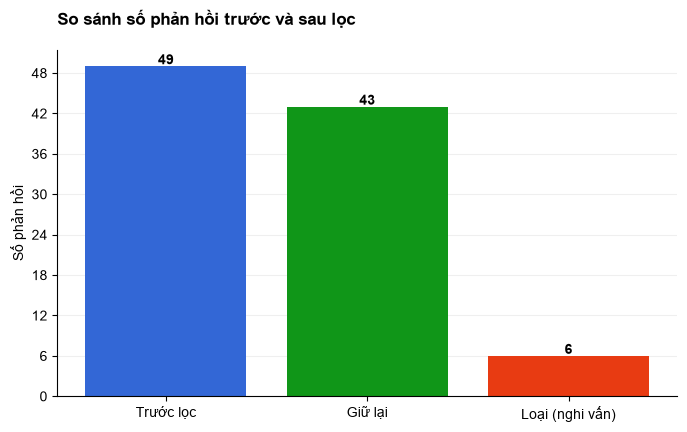

In [15]:
comparison = pd.DataFrame({
    "Trạng thái": ["Trước lọc", "Giữ lại", "Loại (nghi vấn)"],
    "Số phản hồi": [len(raw), len(clean), int(excluded.sum())],
    "Tỷ lệ (%)": [100, len(clean)/len(raw)*100, excluded.mean()*100],
})
display(comparison.style.format({"Tỷ lệ (%)": "{:.1f}"}))
fig, ax = plt.subplots(figsize=(8, 4.5), facecolor="white")
bars = ax.bar(comparison["Trạng thái"], comparison["Số phản hồi"], color=["#3367D6", "#109618", "#E83B12"])
ax.set_title("So sánh số phản hồi trước và sau lọc", loc="left", pad=18)
ax.set_ylabel("Số phản hồi"); ax.yaxis.set_major_locator(MaxNLocator(integer=True)); ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
for bar, value in zip(bars, comparison["Số phản hồi"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+.3, str(value), ha="center", fontweight="bold")
fig.savefig(OUTPUT_DIR / "before_after_filter.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)


## 3. Hàm vẽ

Không hiển thị dòng “câu trả lời” trên biểu đồ. Biểu đồ tròn dùng cho các câu một đáp án; B1–B3 dùng cột nhóm Likert 1–5.


In [16]:
GOOGLE_COLORS = ["#3367D6", "#E83B12", "#FF9800", "#109618", "#990099", "#0099C6", "#DD4477", "#66AA00", "#B82E2E"]
LIKERT_COLORS = ["#3367D6", "#E83B12", "#FF9800", "#109618", "#990099"]
LIKERT_ORDER = ["(1)", "(2)", "(3)", "(4)", "(5)"]

def short(text, width=40):
    return "\n".join(textwrap.wrap(str(text), width=width, break_long_words=False))

def title_without_item(column):
    return re.sub(r"\s*\[.*?\]", "", str(column)).strip()

def save(fig, stem):
    stem = re.sub(r"[^A-Za-z0-9_-]+", "_", stem)
    fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=180, bbox_inches="tight", facecolor="white")
    plt.show(); plt.close(fig)

def pie_chart(series, title, stem):
    counts = series.dropna().astype(str).str.strip()
    counts = counts[counts.ne("")].value_counts()
    if counts.empty: return
    fig, ax = plt.subplots(figsize=(10, 5.8), facecolor="white")
    def pct(p): return f"{p:.1f}%" if p >= 4 else ""
    wedges, _, _ = ax.pie(counts.values, startangle=90, colors=GOOGLE_COLORS[:len(counts)], autopct=pct,
                          textprops={"color":"white", "fontsize":9}, wedgeprops={"edgecolor":"white", "linewidth":1})
    ax.legend(wedges, [short(x, 45) for x in counts.index], loc="center left", bbox_to_anchor=(1.02, .5), frameon=False, fontsize=9)
    ax.set_title(short(title, 85), loc="left", pad=20)
    save(fig, stem)

def likert_group(data, columns, title, stem):
    labels = [re.search(r"\[(.*?)\]", c).group(1) if re.search(r"\[(.*?)\]", c) else title_without_item(c) for c in columns]
    table = pd.DataFrame({c: data[c].astype(str).str.strip().value_counts().reindex(LIKERT_ORDER, fill_value=0) for c in columns}, index=LIKERT_ORDER)
    x = np.arange(len(columns)); width = .78 / len(LIKERT_ORDER)
    fig, ax = plt.subplots(figsize=(max(10, len(columns)*3.1), 5.8), facecolor="white")
    for i, score in enumerate(LIKERT_ORDER):
        ax.bar(x+(i-2)*width, table.loc[score], width, label=score, color=LIKERT_COLORS[i])
    ax.set_xticks(x, [short(label, 24) for label in labels]); ax.set_ylabel("Số phản hồi")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True)); ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
    ax.legend(ncol=5, frameon=False, loc="upper left"); ax.set_title(title, loc="left", pad=18)
    save(fig, stem)


## 4. Xuất biểu đồ trước và sau lọc

Mỗi biểu đồ được xuất hai ảnh `before_*` và `after_*` trong thư mục `tripguardian_ui_charts`.


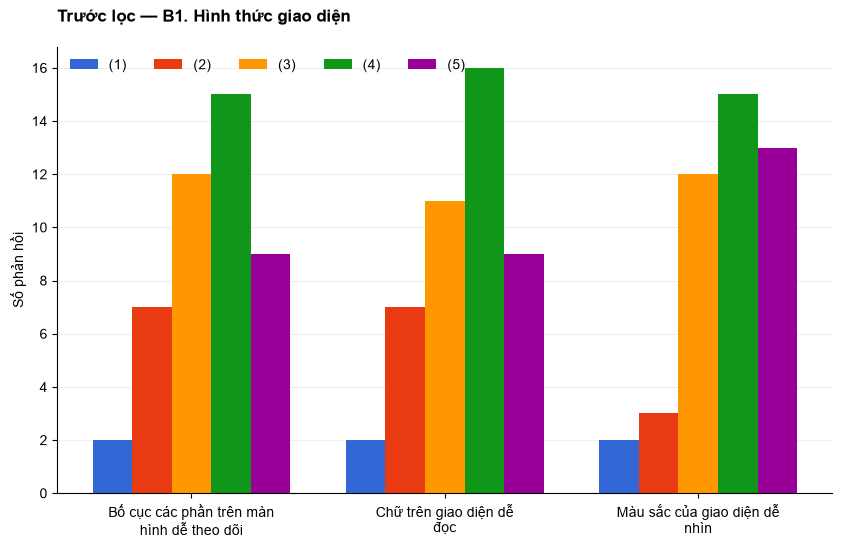

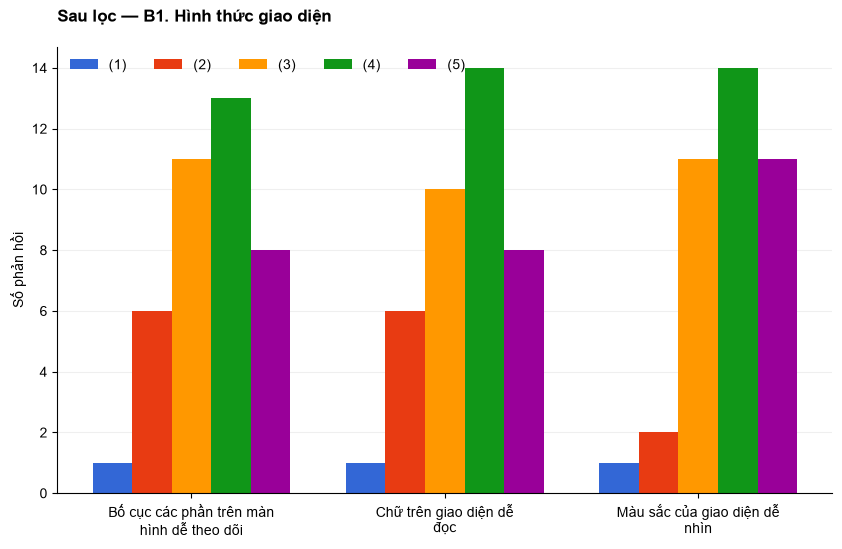

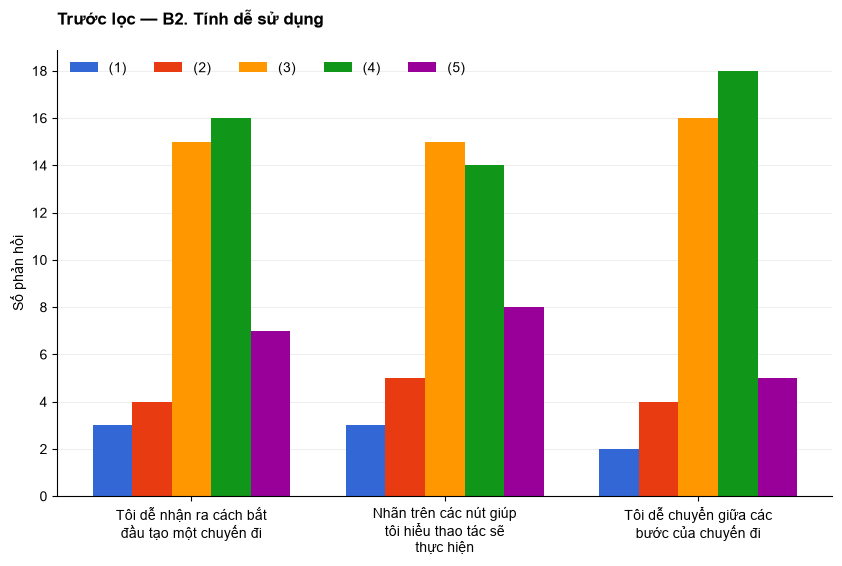

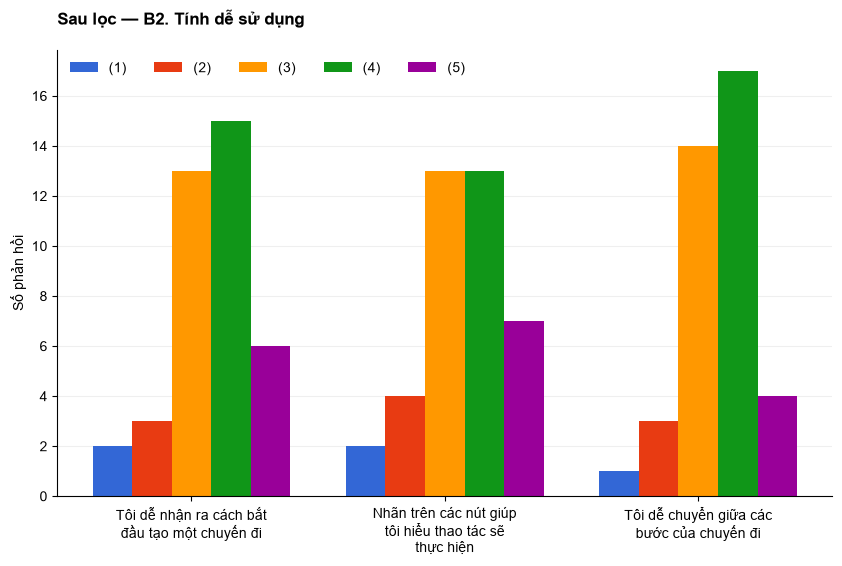

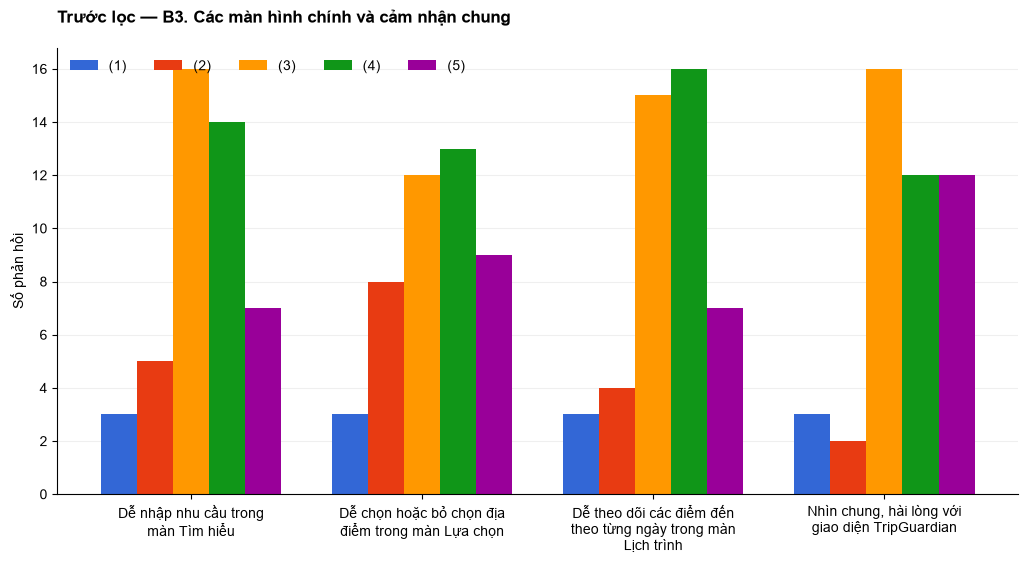

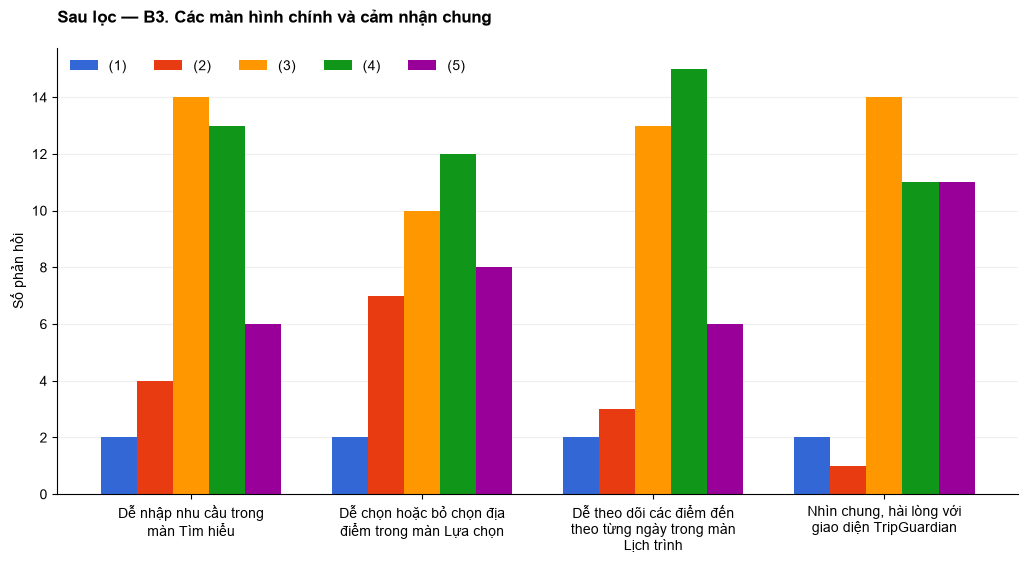

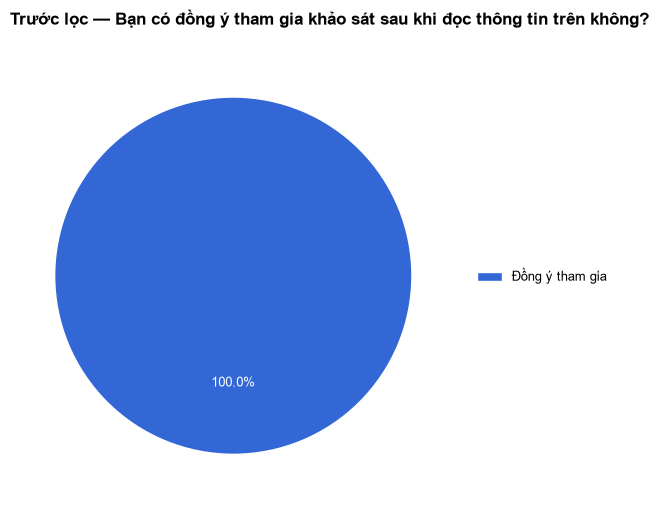

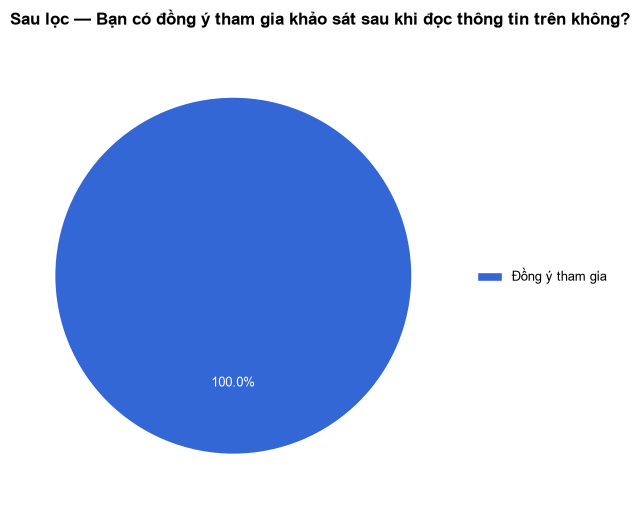

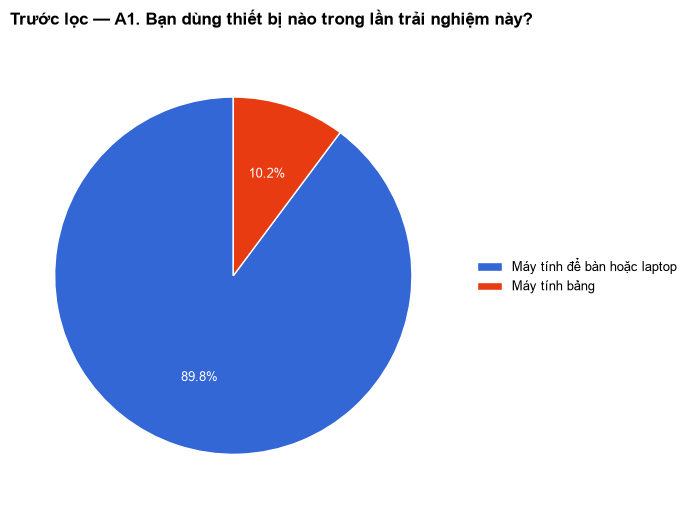

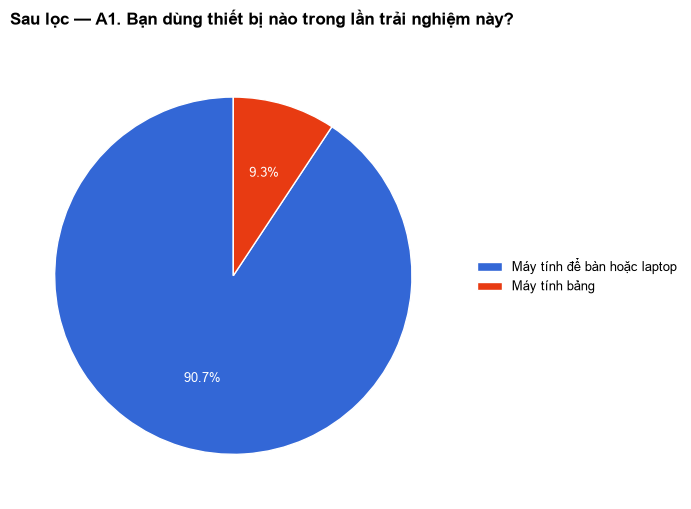

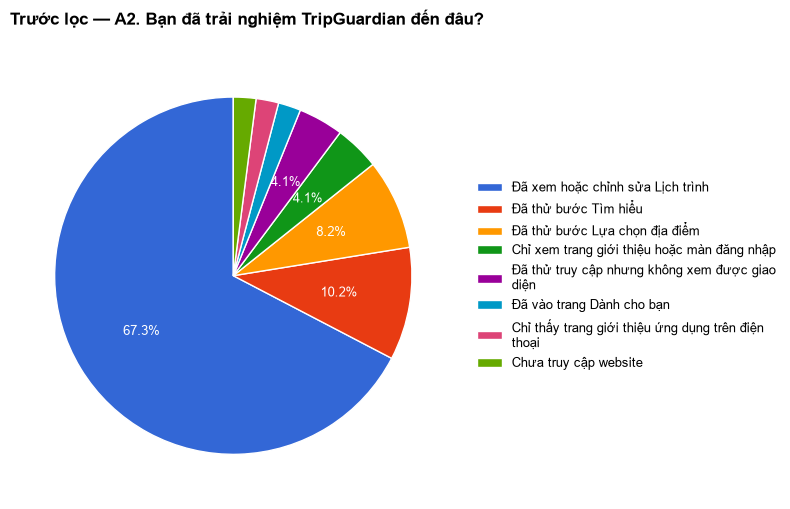

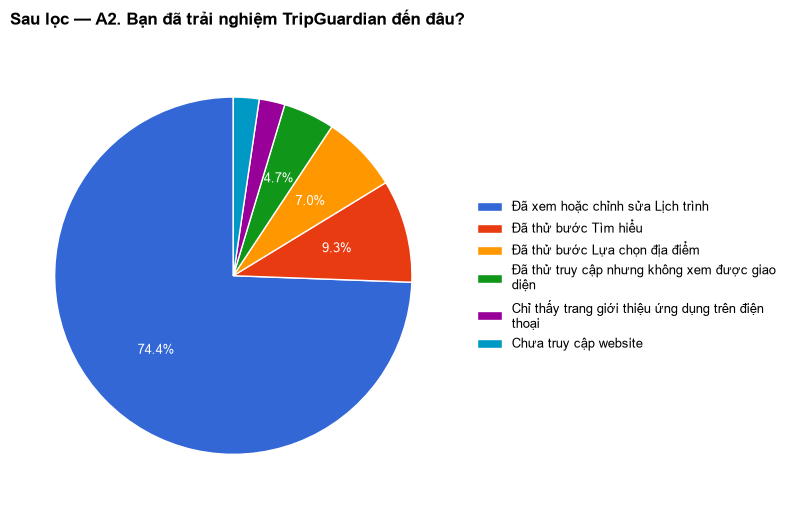

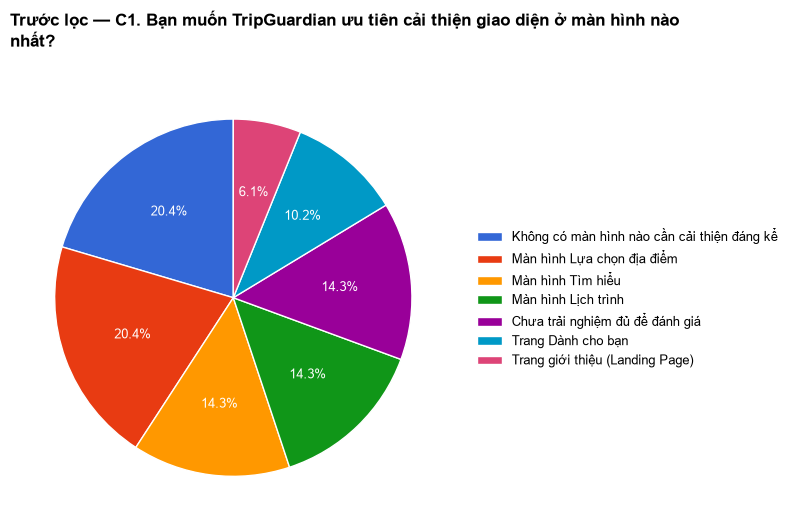

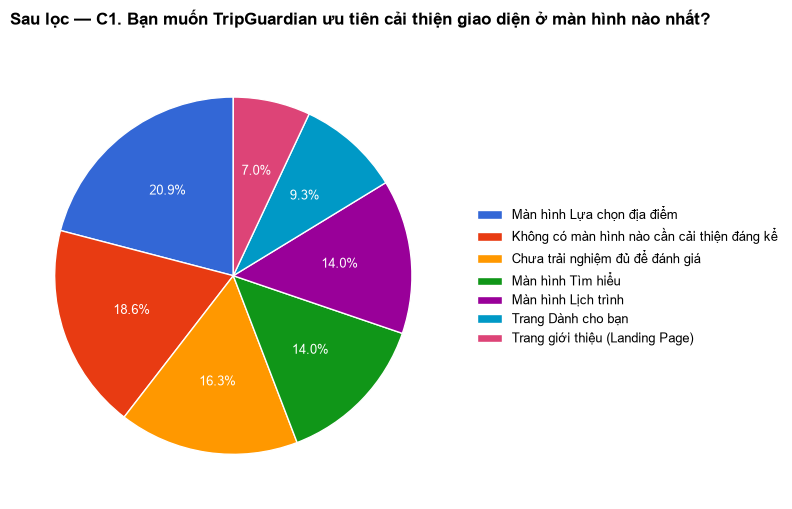

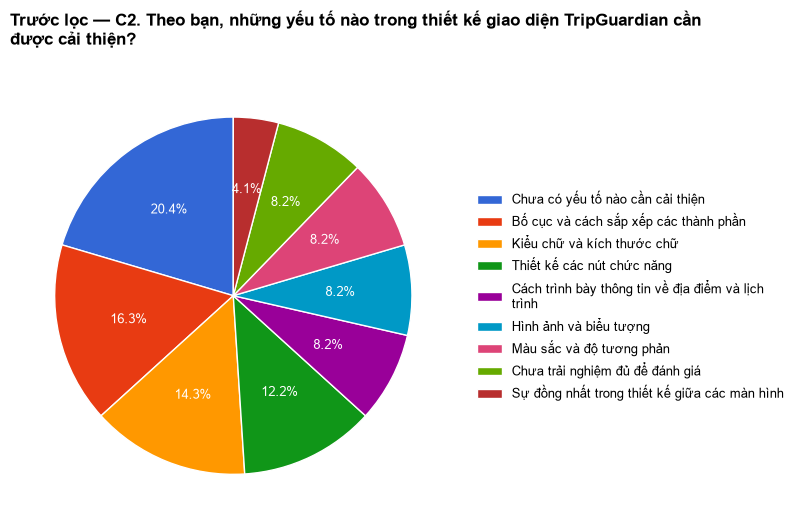

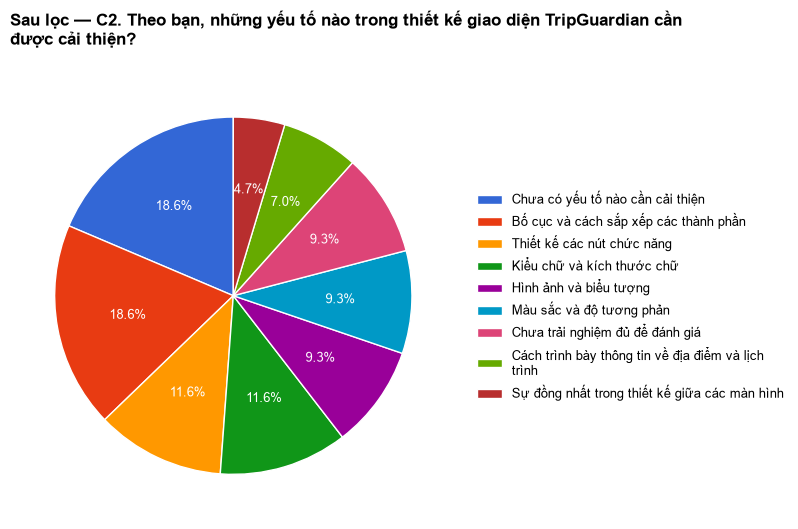

Đã lưu biểu đồ vào: D:\cs\draft\tripguardian_ui_charts


In [17]:
DATASETS_TO_PLOT = {
    "before": raw.drop(columns="_timestamp", errors="ignore"),
    "after": clean,
}

# Biểu đồ Likert B1, B2, B3: trước và sau lọc.
for group in range(1, 4):
    cols = [c for c in clean.columns if re.match(fr"^B{group}\.", c)]
    if cols:
        base_title = title_without_item(cols[0])
        for stage, data in DATASETS_TO_PLOT.items():
            stage_title = "Trước lọc" if stage == "before" else "Sau lọc"
            likert_group(data, cols, f"{stage_title} — {base_title}", f"{stage}_B{group}_Likert")

# Câu đồng ý tham gia, A1, A2, C1, C2: biểu đồ tròn trước và sau lọc.
for i, col in enumerate(clean.columns):
    if col == timestamp_col or re.match(r"^B[1-3]\.", col):
        continue
    match = re.match(r"^([AC]\d+)\.", col)
    question_id = match.group(1) if match else f"question_{i:02d}"
    for stage, data in DATASETS_TO_PLOT.items():
        stage_title = "Trước lọc" if stage == "before" else "Sau lọc"
        pie_chart(data[col], f"{stage_title} — {col}", f"{stage}_{question_id}")

print(f"Đã lưu biểu đồ vào: {OUTPUT_DIR.resolve()}")


## 5. Tóm tắt mẫu trước/sau lọc


In [18]:
summary = pd.DataFrame({
    "Chỉ số": [
        "Phản hồi gốc", "Trùng hoàn toàn", "Chọn một mức Likert xuyên suốt",
        f"Gửi cách phản hồi trước ≤ {RAPID_SECONDS} giây", "Mâu thuẫn mức trải nghiệm",
        f"Dấu vân tay lặp theo cụm (≥ {FINGERPRINT_MIN_CLUSTER_SIZE})", "Phản hồi dùng để vẽ",
    ],
    "Số lượng": [
        len(raw), flags["duplicate_exact"].sum(), flags["straight_lining"].sum(),
        flags["rapid_submission"].sum(), flags["experience_contradiction"].sum(),
        flags["repeated_fingerprint_cluster"].sum(), len(clean),
    ],
})
summary.to_csv(OUTPUT_DIR / "summary.csv", index=False, encoding="utf-8-sig")
summary


,Chỉ số,Số lượng
0,Phản hồi gốc,49
1,Trùng hoàn toàn,0
2,Chọn một mức Likert xuyên suốt,5
3,Gửi cách phản hồi trước ≤ 60 giây,0
4,Mâu thuẫn mức trải nghiệm,2
5,Dấu vân tay lặp theo cụm (≥ 3),0
6,Phản hồi dùng để vẽ,43
